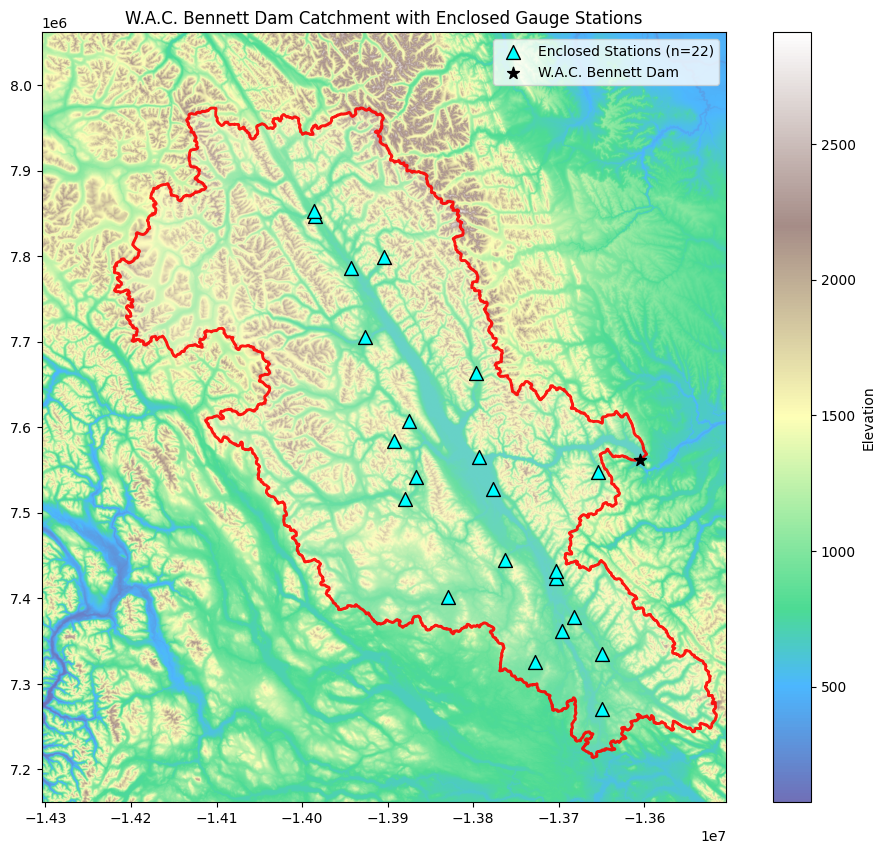

In [7]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from rasterio.enums import Resampling
from rasterio.windows import from_bounds
from rasterio.transform import rowcol
from pysheds.grid import Grid
from pyproj import Transformer
from src.config import RAW_DATA_DIR

# 1. Setup paths and parameters
dem_path = str(RAW_DATA_DIR / 'dem_data/western_canada_dem.tif')
lon, lat = -122.21041, 56.01685

# Load station metadata
station_meta = pd.read_csv(RAW_DATA_DIR / 'station_metadata.csv')

# 20% of original resolution (1/25th the RAM footprint)
scale_factor = 0.2  

# 2. Dynamically handle projection and bounding box
with rasterio.open(dem_path) as src:
    dem_crs = src.crs
    transformer = Transformer.from_crs("EPSG:4326", dem_crs, always_xy=True)
    x_coord, y_coord = transformer.transform(lon, lat)

    # Expanded Bounding Box to capture headwaters
    xmin = x_coord - 700000.0
    xmax = x_coord + 100000.0
    ymin = y_coord - 400000.0
    ymax = y_coord + 500000.0
    
    window = from_bounds(xmin, ymin, xmax, ymax, src.transform)
    
    # 3. Read and downsample on the fly
    out_shape = (
        int(window.height * scale_factor),
        int(window.width * scale_factor)
    )
    
    dem_resampled = src.read(
        1, 
        window=window, 
        out_shape=out_shape, 
        resampling=Resampling.average
    ).astype(np.float32)
    
    # Scale the spatial transform to match the new resolution
    transform = src.window_transform(window)
    new_transform = transform * transform.scale(
        (window.width / out_shape[1]),
        (window.height / out_shape[0])
    )
    
    # Prepare metadata for the temporary file
    profile = src.profile.copy()
    profile.update({
        'height': out_shape[0],
        'width': out_shape[1],
        'transform': new_transform,
        'dtype': 'float32',
        'nodata': src.nodata if src.nodata is not None else -9999.0
    })

# 4. Use a Temporary Directory to bridge rasterio and pysheds
with tempfile.TemporaryDirectory() as tmpdir:
    temp_dem_path = os.path.join(tmpdir, 'resampled_dem.tif')
    
    # Write the resampled array to the temporary file
    with rasterio.open(temp_dem_path, 'w', **profile) as dst:
        dst.write(dem_resampled, 1)
        
    # Pass the string path to pysheds
    grid = Grid.from_raster(temp_dem_path)
    dem = grid.read_raster(temp_dem_path)

    # 5. Condition the downsampled DEM
    pit_filled_dem = grid.fill_pits(dem)
    flooded_dem = grid.fill_depressions(pit_filled_dem)
    inflated_dem = grid.resolve_flats(flooded_dem)

    # 6. Compute Flow Direction & Accumulation
    dirmap = (64, 128, 1, 2, 4, 8, 16, 32)
    fdir = grid.flowdir(inflated_dem, dirmap=dirmap)
    acc = grid.accumulation(fdir, dirmap=dirmap)

    # 7. Snap Pour Point
    x_snap, y_snap = grid.snap_to_mask(acc > 200, (x_coord, y_coord))

    # 8. Delineate the Catchment
    catchment = grid.catchment(x=x_snap, y=y_snap, fdir=fdir, dirmap=dirmap, xytype='coordinate')

# --- NEW: Filter Gauge Stations ---
# Transform station coordinates to the DEM's CRS
station_x, station_y = transformer.transform(
    station_meta['Longitude'].values, 
    station_meta['Latitude'].values
)
station_meta['x_proj'] = station_x
station_meta['y_proj'] = station_y

enclosed_stations = []

# Iterate through stations to check if they fall within the catchment mask
for idx, row_data in station_meta.iterrows():
    # Convert map coordinates to array row/col indices using the resampled transform
    r, c = rowcol(new_transform, row_data['x_proj'], row_data['y_proj'])
    
    # Check if the row/col is within the bounds of our windowed array
    if 0 <= r < catchment.shape[0] and 0 <= c < catchment.shape[1]:
        # If the boolean mask is True at this pixel, the station is inside
        if catchment[r, c]:
            enclosed_stations.append(row_data)

enclosed_df = pd.DataFrame(enclosed_stations)

# 9. Plot the Result
fig, ax = plt.subplots(figsize=(12, 10))

im = ax.imshow(dem, extent=grid.extent, cmap='terrain', alpha=0.7)
plt.colorbar(im, ax=ax, label='Elevation')

# --- FIXED: Added origin='upper' to prevent vertical flipping ---
ax.contour(catchment, levels=[0.5], extent=grid.extent, colors='red', 
           linewidths=2, alpha=0.9, origin='upper')

catchment_mask = np.where(catchment, np.float32(1), np.nan)
ax.imshow(catchment_mask, extent=grid.extent, cmap='Reds', alpha=0.15)

# Plot Enclosed Stations
if not enclosed_df.empty:
    ax.scatter(enclosed_df['x_proj'], enclosed_df['y_proj'], 
               color='cyan', edgecolors='black', marker='^', s=100, 
               label=f'Enclosed Stations (n={len(enclosed_df)})', zorder=5)

ax.scatter(x_snap, y_snap, color='black', s=80, marker='*', label='W.A.C. Bennett Dam', zorder=6)
ax.set_title('W.A.C. Bennett Dam Catchment with Enclosed Gauge Stations')
ax.legend(loc='upper right')
plt.show()